# Mon Pokédex Pokémon : niveau 1

**Module :** Fondements mathématiques de l'IA

**Objectif :** à partir des **6 statistiques de base** d'un Pokémon (PV, Attaque, Défense, Attaque spéciale, Défense spéciale, Vitesse) :

1. le ranger dans un **groupe** de Pokémon au profil similaire (clustering, non supervisé) ;
2. estimer sa **probabilité d'être légendaire** (classification binaire) ;
3. prédire son **type principal** `type1` (classification multiclasse, 18 classes).

Ces trois modèles alimentent l'application `app.py`.

**Plan du notebook**

| Partie | Contenu |
|---|---|
| 0 | Préparation : imports, chargement, nettoyage, fuite de données |
| 1 | Exploration des données (EDA) |
| 2 | Clustering : K-means, CAH, GMM, ACP |
| 3 | Prédiction du statut légendaire |
| 4 | Prédiction du type |
| 5 | Synthèse et choix des modèles |

**Reproductibilité :** toutes les opérations aléatoires utilisent `random_state = 42` (défini une seule fois dans `src/config.py`).

## 0. Préparation

### 0.1 Imports

Le code réutilisable est dans `src/`. Ainsi, le notebook, le script d'entraînement `src/train.py` et l'application utilisent **exactement** le même nettoyage et les mêmes listes de colonnes.

In [1]:
import sys
from pathlib import Path

# Permet d'importer le package src/ depuis le dossier notebook/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (RANDOM_STATE, STATS, PHYSICAL, STAT_LABELS,
                        LEAKY_COLS, TARGET_LEGENDARY, TARGET_TYPE, TYPE_FR)
from src.preprocessing import load_raw, clean, quality_report, leaky_columns, NO_TYPE2
from src.viz import (set_style, save_fig, LEG_PALETTE, LEG_LABELS, COLOR_LEG,
                     COLOR_NON_LEG, CMAP_SEQ, CMAP_DIV, SERIES, INK_2, MUTED)

set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 2)
np.random.seed(RANDOM_STATE)
LABELS6 = [STAT_LABELS[s] for s in STATS]
print("random_state =", RANDOM_STATE)

random_state = 42


### 0.2 Chargement des données brutes

Dataset Kaggle « The Complete Pokemon Dataset » (Rounak Banik) : 801 Pokémon des générations 1 à 7. Les données ont été extraites du site serebii.net.

In [2]:
raw = load_raw()
print(f"{raw.shape[0]} lignes × {raw.shape[1]} colonnes")
raw[["pokedex_number", "name", "type1", "type2", *STATS, "base_total",
     "height_m", "weight_kg", "generation", "is_legendary"]].head()

801 lignes × 41 colonnes


,pokedex_number,name,type1,type2,hp,attack,defense,sp_attack,sp_defense,speed,base_total,height_m,weight_kg,generation,is_legendary
0,1,Bulbasaur,grass,poison,45,49,49,65,65,45,318,0.7,6.9,1,0
1,2,Ivysaur,grass,poison,60,62,63,80,80,60,405,1.0,13.0,1,0
2,3,Venusaur,grass,poison,80,100,123,122,120,80,625,2.0,100.0,1,0
3,4,Charmander,fire,NaN,39,52,43,60,50,65,309,0.6,8.5,1,0
4,5,Charmeleon,fire,NaN,58,64,58,80,65,80,405,1.1,19.0,1,0


### 0.3 Contrôle qualité et nettoyage

Trois points à surveiller :

1. **`capture_rate` est stocké comme du texte** à cause d'une seule valeur mal formée (Minior). Ce Pokémon a deux formes, avec deux taux de capture. On garde le premier nombre (30). La colonne ne servira de toute façon pas aux modèles (voir 0.4).
2. **`type2` manquant** pour 384 Pokémon. Ce n'est pas une donnée perdue : ces Pokémon n'ont qu'**un seul type**. On remplace donc la valeur par la modalité `"aucun"` au lieu de l'imputer.
3. **`height_m` et `weight_kg` manquants pour 20 Pokémon.** Ce sont presque tous des Pokémon qui ont une **forme d'Alola** (Rattata, Vulpix, Exeggutor…), plus Hoopa et Lycanroc, qui ont plusieurs formes. Le site source n'a pas su choisir une seule valeur. On **ne les remplit pas ici** : l'imputation par la médiane se fera dans le *pipeline*, avec la médiane du **train uniquement** (voir 0.4).

In [3]:
bad = raw.loc[pd.to_numeric(raw["capture_rate"], errors="coerce").isna(),
              ["name", "capture_rate"]]
print("Valeur non numérique de capture_rate :")
display(bad)

df = clean(raw)
report = quality_report(df)
print("Valeurs manquantes après nettoyage :", report["manquants"])
print("Pokémon sans second type      :", report["sans_type2"])
print("Doublons de nom               :", report["doublons_nom"])
print("Sans taille ni poids          :", ", ".join(report["pokemon_sans_taille_poids"]))

Valeur non numérique de capture_rate :


,name,capture_rate
773,Minior,30 (Meteorite)255 (Core)


Valeurs manquantes après nettoyage : {'height_m': 20, 'weight_kg': 20}
Pokémon sans second type      : 384
Doublons de nom               : 0
Sans taille ni poids          : Rattata, Raticate, Raichu, Sandshrew, Sandslash, Vulpix, Ninetales, Diglett, Dugtrio, Meowth, Persian, Geodude, Graveler, Golem, Grimer, Muk, Exeggutor, Marowak, Hoopa, Lycanroc


### 0.4 Choix des variables et fuite de données

> **Fuite de données (*data leakage*) :** le modèle utilise, pendant l'entraînement, une information qu'il **n'aura pas** au moment de prédire, ou qui contient déjà la réponse. Les scores obtenus sont alors excellents mais trompeurs : ils s'effondrent en conditions réelles.

Dans l'application, l'utilisateur ne saisit **que les 6 statistiques de base**. Les modèles n'ont donc le droit d'utiliser que ces 6 variables. La taille et le poids seront testés comme une **variante** à comparer.

Toutes les autres colonnes sont exclues, chacune pour une raison précise :

In [4]:
excl = pd.DataFrame({"colonne": list(LEAKY_COLS), "raison de l'exclusion": list(LEAKY_COLS.values())})
against = [c for c in df.columns if c.startswith("against_")]
excl.loc[len(excl)] = [f"against_* ({len(against)} colonnes)",
                       "dégâts reçus par type d'attaque : fonction directe de (type1, type2)"]
print(f"{len(leaky_columns(raw))} colonnes exclues au total")
excl

29 colonnes exclues au total


,colonne,raison de l'exclusion
0,capture_rate,fixé par le jeu : quasi toujours 3 pour les lé...
1,base_egg_steps,nombre de pas pour éclore : très élevé (~30 00...
2,base_happiness,bonheur de base : souvent 0 ou 35 pour les lég...
3,experience_growth,courbe d'XP : « lente » pour presque tous les ...
4,percentage_male,"manquant pour les Pokémon asexués, dont la plu..."
5,classfication,texte descriptif (ex. « Legendary Pokémon »)
6,pokedex_number,les légendaires sont regroupés en fin de génér...
7,base_total,somme exacte des 6 stats : redondante (combina...
8,abilities,talents spécifiques aux légendaires (ex. « Pre...
9,japanese_name,"identifiant, aucune information généralisable"


**Vérification chiffrée : ces colonnes « trichent » vraiment.** Une règle naïve d'une ligne, sans aucun apprentissage, suffit à repérer presque tous les légendaires :

In [5]:
regles = {
    "capture_rate <= 3": df["capture_rate"] <= 3,
    "base_egg_steps >= 20480": df["base_egg_steps"] >= 20480,
    "percentage_male manquant (asexué)": df["percentage_male"].isna(),
}
lignes = []
for nom, pred in regles.items():
    vp = (pred & (df[TARGET_LEGENDARY] == 1)).sum()
    lignes.append({"règle": nom,
                   "rappel (légendaires trouvés)": vp / df[TARGET_LEGENDARY].sum(),
                   "précision (prédits vraiment légendaires)": vp / pred.sum()})
pd.DataFrame(lignes).set_index("règle").style.format("{:.0%}")

,rappel (légendaires trouvés),précision (prédits vraiment légendaires)
règle,,
capture_rate <= 3,76%,91%
base_egg_steps >= 20480,90%,97%
percentage_male manquant (asexué),90%,64%


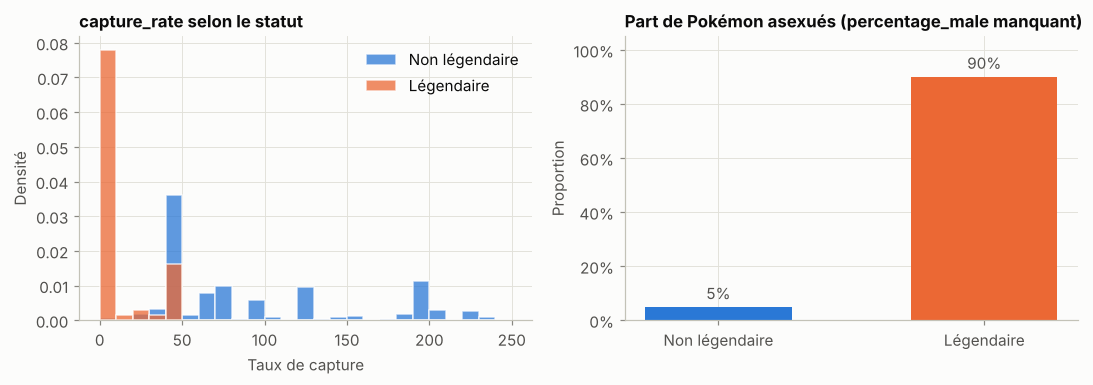

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

ax = axes[0]
for k in (0, 1):
    vals = df.loc[df[TARGET_LEGENDARY] == k, "capture_rate"]
    ax.hist(vals, bins=np.arange(0, 260, 10), color=LEG_PALETTE[k], alpha=0.75,
            label=LEG_LABELS[k], density=True, edgecolor="white", linewidth=1)
ax.set(title="capture_rate selon le statut", xlabel="Taux de capture", ylabel="Densité")
ax.legend()

ax = axes[1]
taux = df["percentage_male"].isna().groupby(df[TARGET_LEGENDARY]).mean()
bars = ax.bar([LEG_LABELS[k] for k in taux.index], taux.values,
              color=[LEG_PALETTE[k] for k in taux.index], width=0.55)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in taux.values], padding=3, color=INK_2)
ax.set(title="Part de Pokémon asexués (percentage_male manquant)", ylim=(0, 1.05),
       ylabel="Proportion")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.tight_layout()
save_fig(fig, "01_fuite_de_donnees")
plt.show()

**Conclusion.** `capture_rate` vaut 3 pour 53 des 70 légendaires, et `base_egg_steps` dépasse 20 000 pas pour 63 d'entre eux. Avec ces variables, un modèle afficherait des scores quasi parfaits sans rien apprendre des **statistiques**, et il serait inutilisable dans l'appli, qui ne reçoit pas ces informations. Les colonnes `against_*` posent le même problème pour la prédiction du type : elles sont **calculées à partir du type**.

`base_total` est exclue pour une autre raison : c'est **exactement** la somme des 6 stats. Une variable qui est une combinaison linéaire exacte des autres n'apporte aucune information nouvelle. En régression logistique, elle crée de plus une colinéarité parfaite : les coefficients ne sont plus identifiables. Elle reste en revanche très utile pour l'**analyse**.

## 1. Exploration des données (EDA)

### 1.1 Distribution des 6 statistiques

In [7]:
desc = df[STATS].describe().T
desc["asymétrie"] = df[STATS].skew()
desc.rename(index=STAT_LABELS)

,count,mean,std,min,25%,50%,75%,max,asymétrie
PV,801.0,68.96,26.58,1.0,50.0,65.0,80.0,255.0,1.83
Attaque,801.0,77.86,32.16,5.0,55.0,75.0,100.0,185.0,0.53
Défense,801.0,73.01,30.77,5.0,50.0,70.0,90.0,230.0,1.12
Att. Spé.,801.0,71.31,32.35,10.0,45.0,65.0,91.0,194.0,0.78
Déf. Spé.,801.0,70.91,27.94,20.0,50.0,66.0,90.0,230.0,0.87
Vitesse,801.0,66.33,28.91,5.0,45.0,65.0,85.0,180.0,0.44


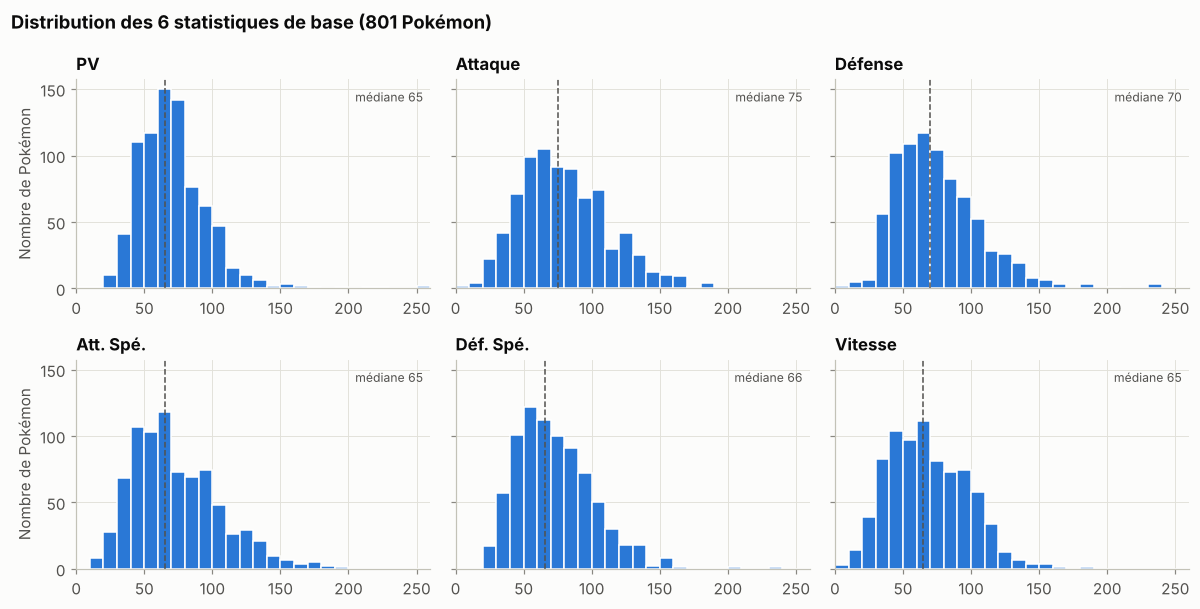

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), sharey=True)
for ax, s in zip(axes.flat, STATS):
    ax.hist(df[s], bins=np.arange(0, 265, 10), color=COLOR_NON_LEG,
            edgecolor="white", linewidth=1)
    med = df[s].median()
    ax.axvline(med, color=INK_2, lw=1, ls="--")
    ax.text(0.98, 0.95, f"médiane {med:.0f}", transform=ax.transAxes,
            color=INK_2, fontsize=8, ha="right", va="top")
    ax.set_title(STAT_LABELS[s])
    ax.set_xlim(0, 260)
for ax in axes[:, 0]:
    ax.set_ylabel("Nombre de Pokémon")
fig.suptitle("Distribution des 6 statistiques de base (801 Pokémon)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_distributions_stats")
plt.show()

In [9]:
# Valeurs extrêmes : qui sont les Pokémon hors normes ?
pd.DataFrame({STAT_LABELS[s]: df.nlargest(3, s).apply(lambda r: f"{r['name']} ({r[s]})", axis=1).values
              for s in STATS}, index=["1er", "2e", "3e"])

,PV,Attaque,Défense,Att. Spé.,Déf. Spé.,Vitesse
1er,Blissey (255),Heracross (185),Steelix (230),Mewtwo (194),Shuckle (230),Deoxys (180)
2e,Chansey (250),Kartana (181),Shuckle (230),Kyogre (180),Regice (200),Ninjask (160)
3e,Guzzlord (223),Groudon (180),Aggron (230),Rayquaza (180),Kyogre (160),Pheromosa (151)


**Lecture**

- Les 6 stats ont des **ordres de grandeur comparables** (moyennes de 66 à 78, écarts-types de 27 à 32). Elles ne sont pourtant **pas** sur la même échelle : les PV vont de 1 à 255, la Défense spéciale de 20 à 230.
- Toutes les distributions sont **asymétriques à droite** : beaucoup de Pokémon moyens et une queue de Pokémon très forts. C'est le cas surtout des **PV** (asymétrie 1,8) et de la **Défense** (1,1).
- Les valeurs extrêmes sont **réelles**, pas des erreurs : Leuphorie (Blissey, 255 PV), Caratroc (Shuckle, 230 en Défense et en Défense spéciale), Mewtwo (194 en Attaque spéciale). On les **garde**, car ils font partie de ce que l'appli doit savoir traiter.

**Conséquence : standardiser avant toute méthode fondée sur une distance.** On applique le z-score $z = \dfrac{x - \mu}{\sigma}$, où $\mu$ et $\sigma$ sont calculés **sur le train**. K-means, k-NN et SVM utilisent la distance euclidienne $d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_j (x_j - y_j)^2}$. Sans standardisation, une variable plus dispersée pèserait davantage dans la distance, sans que cela ait un sens.

**Remarque :** le dataset donne pour certains Pokémon les stats de leur **méga-évolution** (Florizarre : 625 au total, Dracaufeu : 634…). Il faudra le garder en tête lors de l'interprétation : ces Pokémon paraîtront « quasi légendaires ».

### 1.2 Les légendaires ont-ils des stats différentes ?

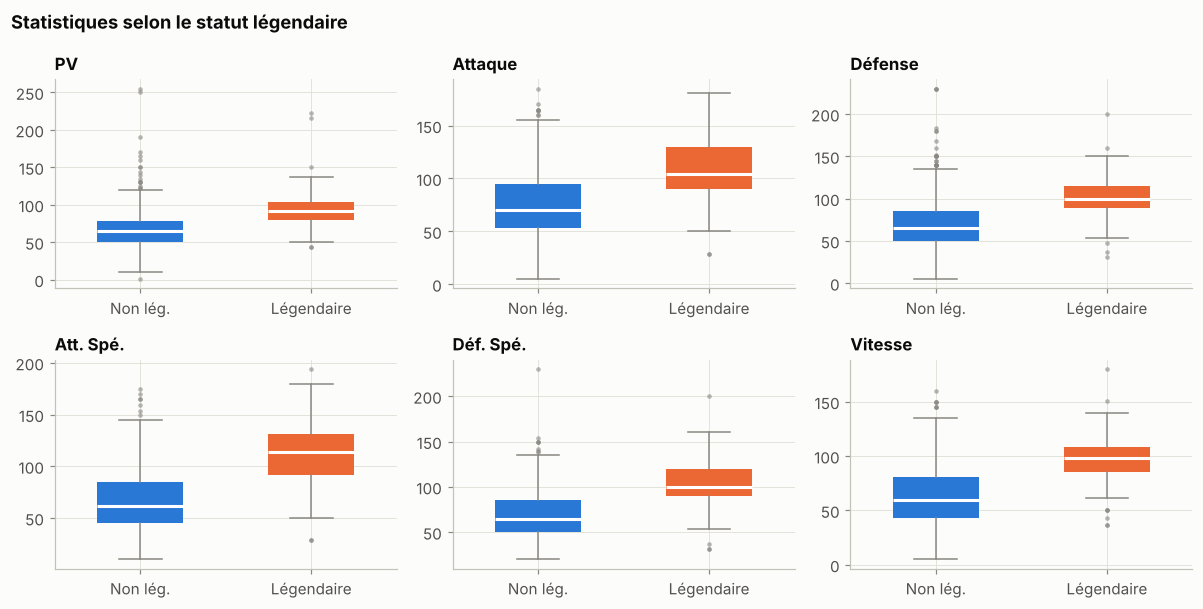

,PV,Attaque,Défense,Att. Spé.,Déf. Spé.,Vitesse,base_total
is_legendary,,,,,,,
Non légendaire,65.0,70.0,65.0,62.0,65.0,60.0,418.0
Légendaire,91.0,104.0,100.0,114.0,100.0,98.0,600.0


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, s in zip(axes.flat, STATS):
    data = [df.loc[df[TARGET_LEGENDARY] == k, s] for k in (0, 1)]
    bp = ax.boxplot(data, tick_labels=["Non lég.", "Légendaire"], widths=0.5,
                    patch_artist=True, medianprops=dict(color="white", lw=2),
                    flierprops=dict(marker="o", ms=3, mfc=MUTED, mec="none", alpha=0.6),
                    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for patch, k in zip(bp["boxes"], (0, 1)):
        patch.set_facecolor(LEG_PALETTE[k])
        patch.set_edgecolor("none")
    ax.set_title(STAT_LABELS[s])
fig.suptitle("Statistiques selon le statut légendaire", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_stats_par_statut")
plt.show()

df.groupby(TARGET_LEGENDARY)[STATS + ["base_total"]].median().rename(
    index=LEG_LABELS, columns=STAT_LABELS)

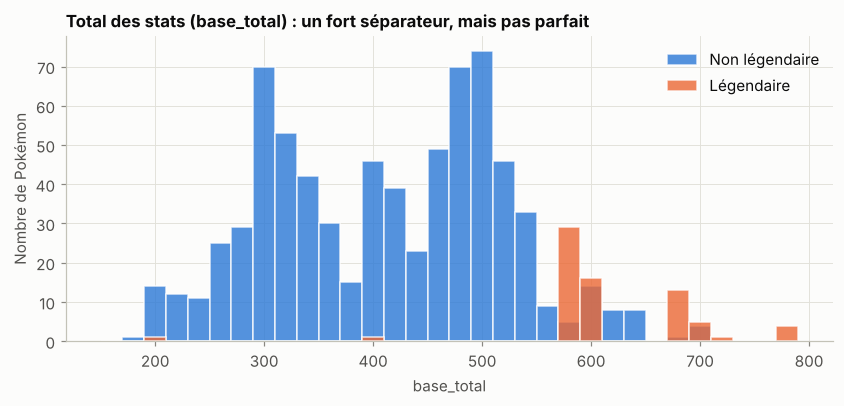

Non légendaires avec base_total >= 600 : 31
    Venusaur, Charizard, Blastoise, Alakazam, Gengar, Pinsir, Gyarados, Aerodactyl, Dragonite, Ampharos, Steelix, Scizor, Heracross, Houndoom, Tyranitar, Sceptile, Blaziken, Swampert, Gardevoir, Slaking, Aggron, Salamence, Metagross, Garchomp, Lucario, Gallade, Hydreigon, Greninja, Goodra, Wishiwashi, Kommo-o
Légendaires avec base_total < 570      : 2
    Cosmog (200), Cosmoem (400)


In [11]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(150, 800, 20)
for k in (0, 1):
    ax.hist(df.loc[df[TARGET_LEGENDARY] == k, "base_total"], bins=bins, alpha=0.8,
            color=LEG_PALETTE[k], label=LEG_LABELS[k], edgecolor="white", linewidth=1)
ax.set(title="Total des stats (base_total) : un fort séparateur, mais pas parfait",
       xlabel="base_total", ylabel="Nombre de Pokémon")
ax.legend()
save_fig(fig, "04_base_total_par_statut")
plt.show()

chev = df[(df[TARGET_LEGENDARY] == 0) & (df["base_total"] >= 600)]
faibles = df[(df[TARGET_LEGENDARY] == 1) & (df["base_total"] < 570)]
print(f"Non légendaires avec base_total >= 600 : {len(chev)}")
print("   ", ", ".join(chev['name']))
print(f"Légendaires avec base_total < 570      : {len(faibles)}")
print("   ", ", ".join(f"{n} ({t})" for n, t in faibles[['name', 'base_total']].values))

**Lecture**

- Les légendaires sont **nettement plus forts sur les 6 stats**. Leur total médian est de 600, contre 418 pour les autres. L'écart le plus marqué concerne l'**Attaque spéciale** (114 contre 62).
- La séparation n'est pourtant **pas parfaite**. Les deux histogrammes se chevauchent autour de 580–680, à cause de deux groupes de Pokémon :
  - des **non-légendaires très forts** : les « pseudo-légendaires » (Dracolosse, Tyranocif, Métalosse, Carchacrok…) et des méga-évolutions ;
  - quelques **légendaires faibles** : Cosmog (200) et Cosmovum (400), formes de bébé de Solgaleo et Lunala, et les Tokos et plusieurs Ultra-Chimères, à 570 tout juste.
- **Conséquence pour l'étape 3 :** les stats seules permettront une bonne prédiction, mais pas parfaite. Les erreurs seront prévisibles : des pseudo-légendaires pris pour des légendaires, et inversement. Ce chevauchement justifie aussi d'afficher une **probabilité** plutôt qu'un verdict oui/non.

### 1.3 Corrélations entre les statistiques

On calcule deux coefficients :

- **Pearson** $r = \dfrac{\mathrm{cov}(X, Y)}{\sigma_X \sigma_Y}$ mesure une relation **linéaire**. Il est sensible aux valeurs extrêmes.
- **Spearman** est la corrélation de Pearson calculée sur les **rangs**. Il mesure une relation **monotone** et résiste aux valeurs extrêmes (Leuphorie, Caratroc…).

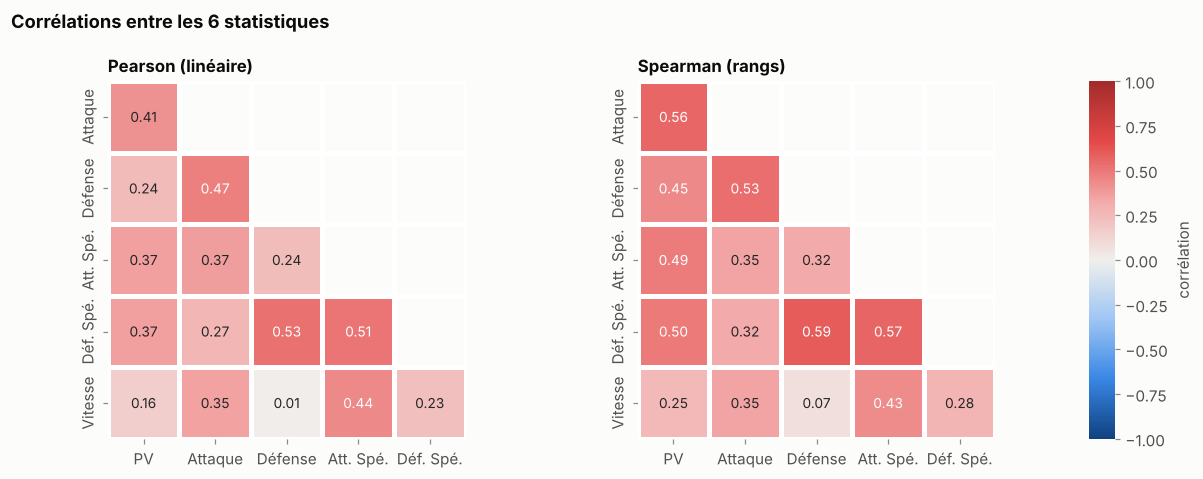

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4.4), gridspec_kw=dict(width_ratios=[1, 1, 0.05]))
for ax, meth, titre in zip(axes[:2], ["pearson", "spearman"], ["Pearson (linéaire)", "Spearman (rangs)"]):
    c = df[STATS].corr(method=meth)
    # on masque la diagonale (toujours 1) et le triangle supérieur (symétrique)
    mask = np.triu(np.ones_like(c, dtype=bool), k=0)
    sns.heatmap(c.iloc[1:, :-1], mask=mask[1:, :-1], annot=True, fmt=".2f", cmap=CMAP_DIV,
                vmin=-1, vmax=1, square=True, linewidths=2, linecolor="white",
                cbar=ax is axes[1], cbar_ax=axes[2] if ax is axes[1] else None,
                cbar_kws=dict(label="corrélation"),
                xticklabels=LABELS6[:-1], yticklabels=LABELS6[1:], ax=ax,
                annot_kws=dict(fontsize=9))
    ax.set_title(titre)
    ax.grid(False)
fig.suptitle("Corrélations entre les 6 statistiques", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "05_correlations")
plt.show()

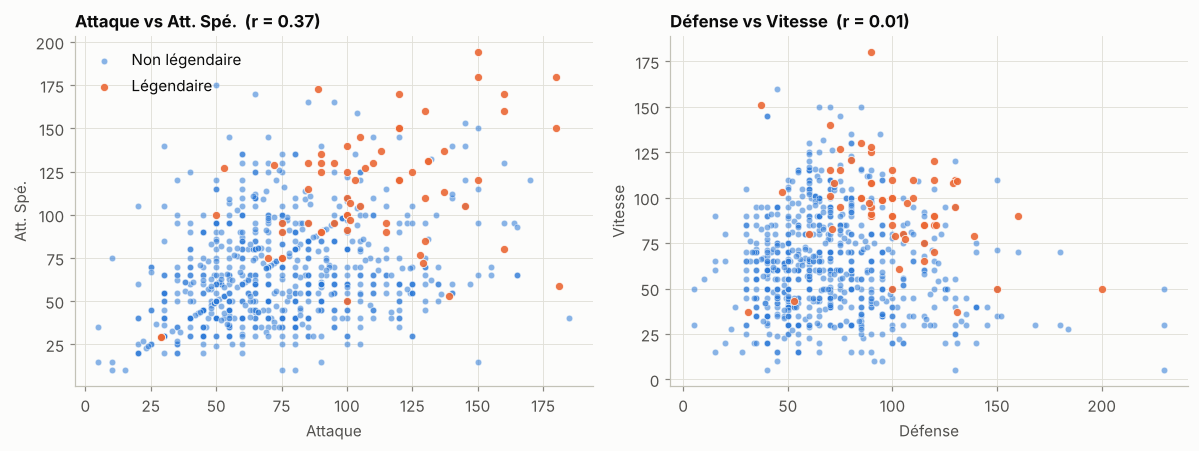

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
paires = [("attack", "sp_attack"), ("defense", "speed")]
for ax, (a, b) in zip(axes, paires):
    for k in (0, 1):
        sub = df[df[TARGET_LEGENDARY] == k]
        ax.scatter(sub[a], sub[b], s=18 if k == 0 else 28, color=LEG_PALETTE[k],
                   alpha=0.55 if k == 0 else 0.9, edgecolor="white", linewidth=0.5,
                   label=LEG_LABELS[k])
    r = df[[a, b]].corr().iloc[0, 1]
    ax.set(xlabel=STAT_LABELS[a], ylabel=STAT_LABELS[b],
           title=f"{STAT_LABELS[a]} vs {STAT_LABELS[b]}  (r = {r:.2f})")
axes[0].legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "06_nuages_points")
plt.show()

**Lecture**

- **Toutes les corrélations sont positives** (de 0,01 à 0,53 avec Pearson). Un Pokémon fort dans une stat a tendance à l'être dans les autres. On peut y voir un **facteur général de « puissance »**, lié au stade d'évolution et au statut légendaire. Ce sera la première composante principale de l'ACP à l'étape 2.
- Les paires les plus corrélées suivent la logique du jeu : **Défense et Défense spéciale** (0,53), **Attaque spéciale et Défense spéciale** (0,51), **Attaque et Défense** (0,47).
- **Défense et Vitesse sont indépendantes** (r = 0,01). C'est le compromis classique entre un Pokémon lent et blindé et un Pokémon rapide et fragile. Cet axe devrait faire apparaître des groupes au clustering.
- Spearman donne des valeurs un peu plus élevées que Pearson (par exemple PV–Attaque : 0,56 contre 0,41). Les valeurs extrêmes, comme Leuphorie avec ses 255 PV mais 10 en Attaque, **affaiblissent** donc la corrélation linéaire.
- Aucune corrélation ne dépasse 0,6 : **aucune stat n'est redondante**, on garde les 6.

### 1.4 Répartition des types

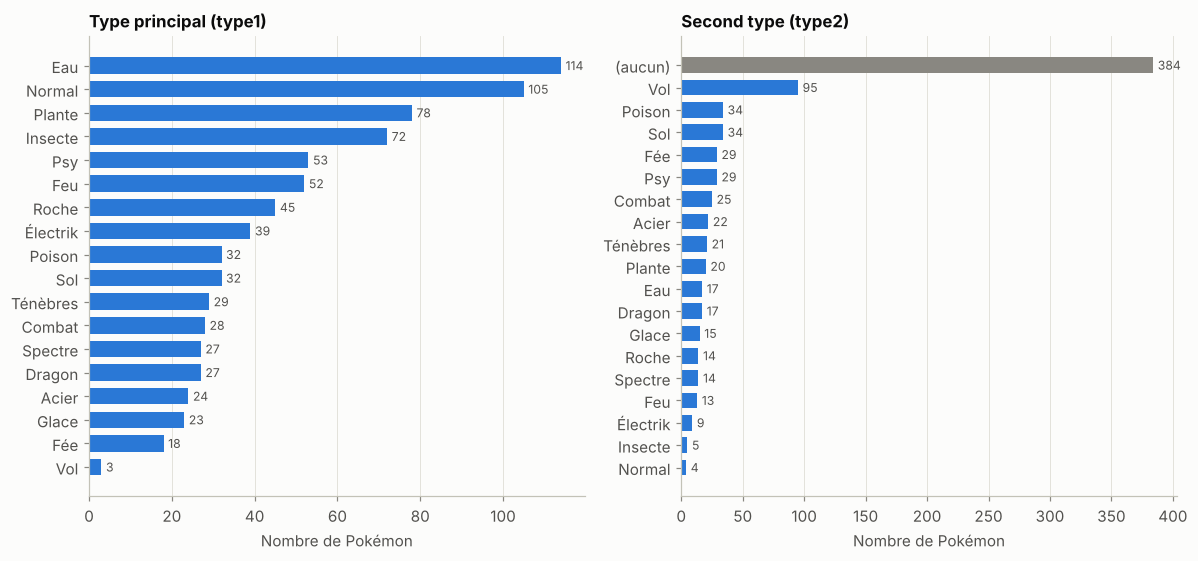

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
t1 = df["type1"].map(TYPE_FR).value_counts()
t2 = df["type2"].map(TYPE_FR).value_counts()
for ax, counts, titre in zip(axes, [t1, t2], ["Type principal (type1)", "Second type (type2)"]):
    counts = counts.sort_values()
    colors = [MUTED if i == TYPE_FR[NO_TYPE2] else COLOR_NON_LEG for i in counts.index]
    bars = ax.barh(counts.index, counts.values, color=colors, height=0.7)
    ax.bar_label(bars, padding=3, fontsize=8, color=INK_2)
    ax.set_title(titre)
    ax.set_xlabel("Nombre de Pokémon")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "07_repartition_types")
plt.show()

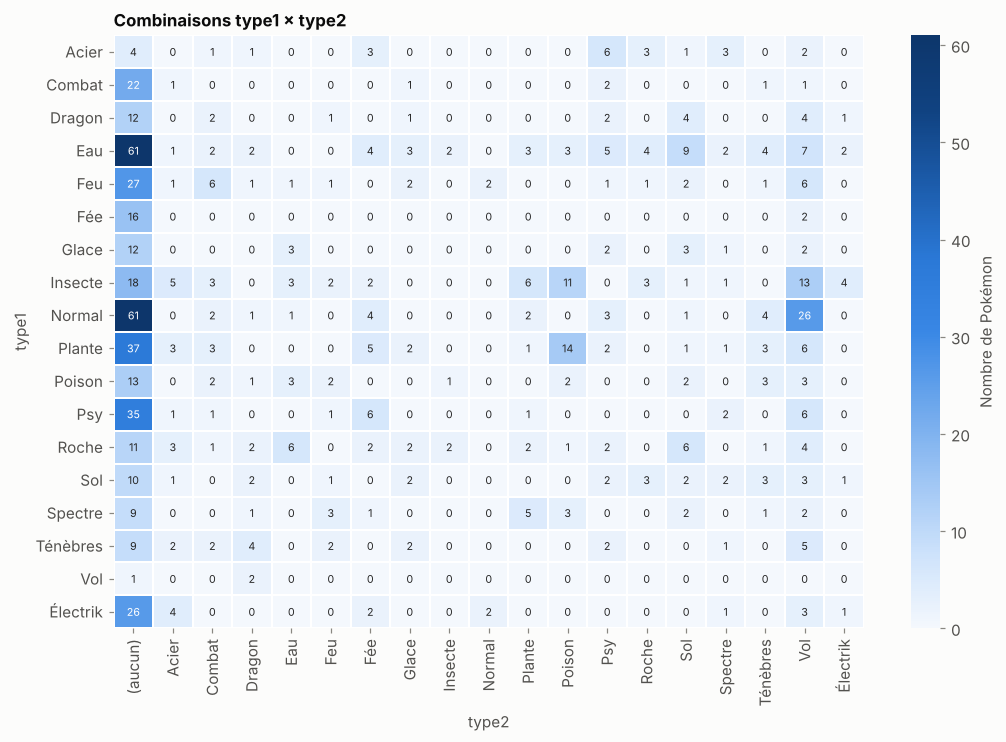

In [15]:
ct = pd.crosstab(df["type1"].map(TYPE_FR), df["type2"].map(TYPE_FR))
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(ct, annot=True, fmt="d", cmap=CMAP_SEQ, linewidths=1, linecolor="white",
            cbar_kws=dict(label="Nombre de Pokémon"), annot_kws=dict(fontsize=7), ax=ax)
ax.set(title="Combinaisons type1 × type2", xlabel="type2", ylabel="type1")
ax.grid(False)
save_fig(fig, "08_type1_x_type2")
plt.show()

**Lecture**

- Les classes de `type1` sont **très déséquilibrées** : Eau (114), Normal (105) et Plante (78) dominent, tandis que Fée (18) et surtout **Vol (3)** sont rares.
- **Vol est un cas particulier.** Seulement 3 Pokémon l'ont comme type principal, mais 95 l'ont comme second type (par exemple Normal/Vol pour les oiseaux du début de jeu). Avec 3 exemples, aucun modèle ne pourra apprendre ce type. De plus, une validation croisée stratifiée à 5 plis demande au moins 5 exemples par classe. **Nous réglerons ce point à l'étape 4.**
- 48 % des Pokémon n'ont pas de second type (`aucun`).
- Les combinaisons les plus fréquentes sont Normal/Vol, Plante/Poison et Insecte/Vol.

### 1.5 Profil statistique moyen par type

Pour chaque type, on calcule la moyenne de chaque stat, exprimée en **z-score** par rapport à l'ensemble des Pokémon. La valeur $+1$ signifie : un écart-type au-dessus de la moyenne générale. Ce tableau indique **à l'avance** quels types les stats pourront reconnaître.

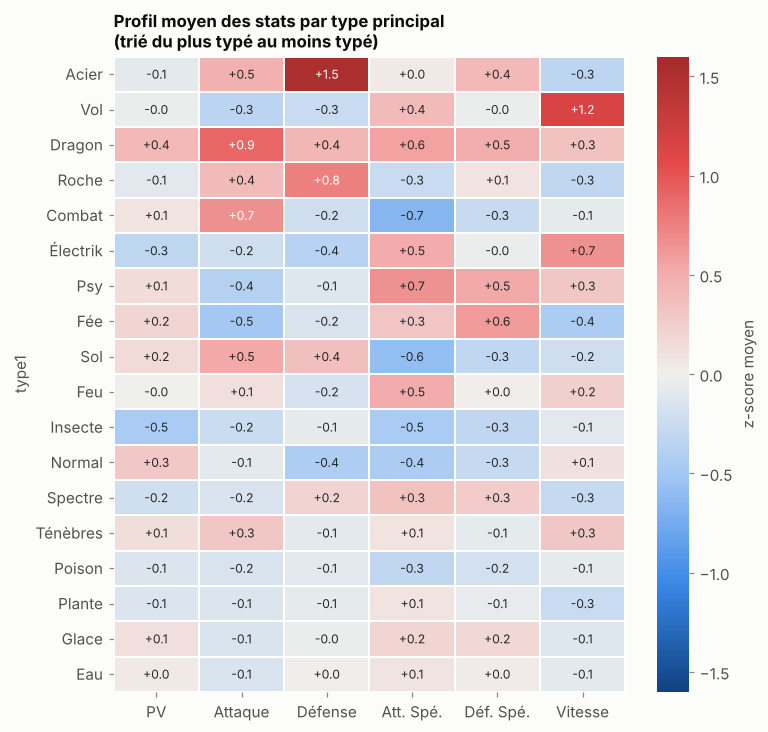

In [16]:
prof = df.groupby(df["type1"].map(TYPE_FR))[STATS].mean()
prof_z = (prof - df[STATS].mean()) / df[STATS].std()
prof_z = prof_z.loc[prof_z.abs().max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7.5, 7.5))
sns.heatmap(prof_z, annot=True, fmt="+.1f", cmap=CMAP_DIV, vmin=-1.6, vmax=1.6, center=0,
            linewidths=1, linecolor="white", xticklabels=LABELS6,
            cbar_kws=dict(label="z-score moyen"), annot_kws=dict(fontsize=8), ax=ax)
ax.set(title="Profil moyen des stats par type principal\n(trié du plus typé au moins typé)",
       ylabel="type1", xlabel="")
ax.grid(False)
save_fig(fig, "09_profil_stats_par_type")
plt.show()

**Lecture : certains types ont une « signature » statistique, d'autres non.**

| Type | Signature | Pourquoi (logique du jeu) |
|---|---|---|
| Acier | Défense **+1,5** | carapaces métalliques (Steelix, Airmure…) |
| Vol | Vitesse **+1,2** | mais seulement 3 Pokémon, donc peu fiable |
| Roche | Défense +0,8, Vitesse −0,3 | lents et blindés |
| Dragon | tout positif, Attaque +0,9 | beaucoup de légendaires et de pseudo-légendaires |
| Combat | Attaque +0,7, Att. Spé. **−0,7** | attaquants physiques purs |
| Psy | Att. Spé. +0,7, Déf. Spé. +0,5, Attaque −0,4 | attaquants spéciaux |
| Électrik | Vitesse +0,7, Att. Spé. +0,5 | rapides et spéciaux |
| Fée | Déf. Spé. +0,6, Attaque −0,5 | défenseurs spéciaux |
| **Eau, Plante, Poison, Glace** | **tout proche de 0** | profils variés, sans signature |

**Conséquence pour l'étape 4 :** on peut s'attendre à reconnaître correctement l'Acier, la Roche, le Combat, le Psy et l'Électrik. **Eau** et **Normal**, pourtant les types les plus nombreux, n'ont pas de profil distinctif : ils seront confondus avec tous les autres. Le type d'un Pokémon est d'abord un choix **thématique** (son apparence, son élément), pas statistique. Il faut donc s'attendre à une précision modeste.

### 1.6 Les légendaires : un fort déséquilibre de classes

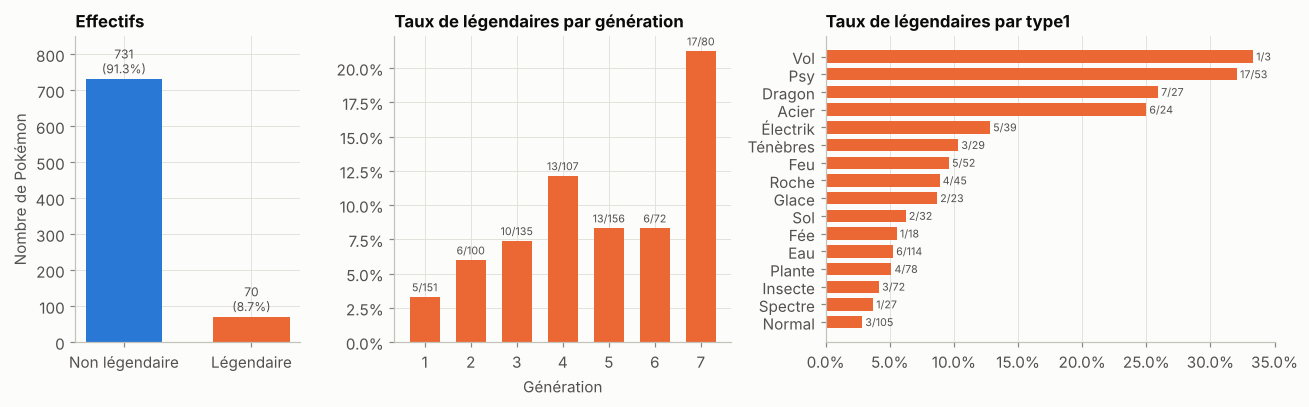

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[0.8, 1.2, 1.6]))

ax = axes[0]
cnt = df[TARGET_LEGENDARY].value_counts().sort_index()
bars = ax.bar([LEG_LABELS[k] for k in cnt.index], cnt.values,
              color=[LEG_PALETTE[k] for k in cnt.index], width=0.6)
ax.bar_label(bars, labels=[f"{v}\n({v / len(df):.1%})" for v in cnt.values], padding=2,
             color=INK_2, fontsize=8)
ax.set(title="Effectifs", ylabel="Nombre de Pokémon", ylim=(0, 850))

ax = axes[1]
g = df.groupby("generation")[TARGET_LEGENDARY].agg(["mean", "sum", "size"])
bars = ax.bar(g.index.astype(str), g["mean"], color=COLOR_LEG, width=0.65)
ax.bar_label(bars, labels=[f"{s}/{n}" for s, n in zip(g["sum"], g["size"])], padding=2,
             fontsize=7, color=INK_2)
ax.set(title="Taux de légendaires par génération", xlabel="Génération")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))

ax = axes[2]
t = df.groupby(df["type1"].map(TYPE_FR))[TARGET_LEGENDARY].agg(["mean", "sum", "size"]).sort_values("mean")
t = t[t["sum"] > 0]
bars = ax.barh(t.index, t["mean"], color=COLOR_LEG, height=0.7)
ax.bar_label(bars, labels=[f"{s}/{n}" for s, n in zip(t["sum"], t["size"])], padding=2,
             fontsize=7, color=INK_2)
ax.set(title="Taux de légendaires par type1")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "10_legendaires")
plt.show()

**Lecture**

- **70 légendaires sur 801, soit 8,7 %.** Un modèle « paresseux » qui répondrait toujours « non légendaire » obtiendrait **91,3 % d'accuracy** sans avoir rien appris. C'est pourquoi l'accuracy seule ne suffit pas pour évaluer le modèle. On utilisera à l'étape 3 :
  - le **rappel** : la part des légendaires retrouvés ;
  - la **précision** : la part des Pokémon prédits légendaires qui le sont vraiment ;
  - le **F1**, la **PR-AUC** et la matrice de confusion.
- Le taux de légendaires **augmente avec les générations** : 3 % en génération 1, 21 % en génération 7 (les Ultra-Chimères, Tokorico…). On n'utilise **pas** la génération comme variable, car elle n'est pas saisie dans l'appli. En revanche, cette dérive dans le temps sera une **limite** à mentionner dans le rapport.
- Les légendaires sont concentrés chez les **Psy** (17 sur 53), **Dragon** (7 sur 27) et **Acier** (6 sur 24). Le type et le statut légendaire sont donc liés, ce qu'on retrouvera au croisement avec les clusters.
- **Ce qu'on en tire pour la suite :**
  - **découpage stratifié**, pour garder 8,7 % de légendaires dans le train et dans le test (on obtient 56 légendaires sur 640 et 14 sur 161) ;
  - **validation croisée stratifiée** ;
  - pondération des classes (`class_weight="balanced"`) ou suréchantillonnage (SMOTE).

### 1.7 Taille et poids (variante à comparer)

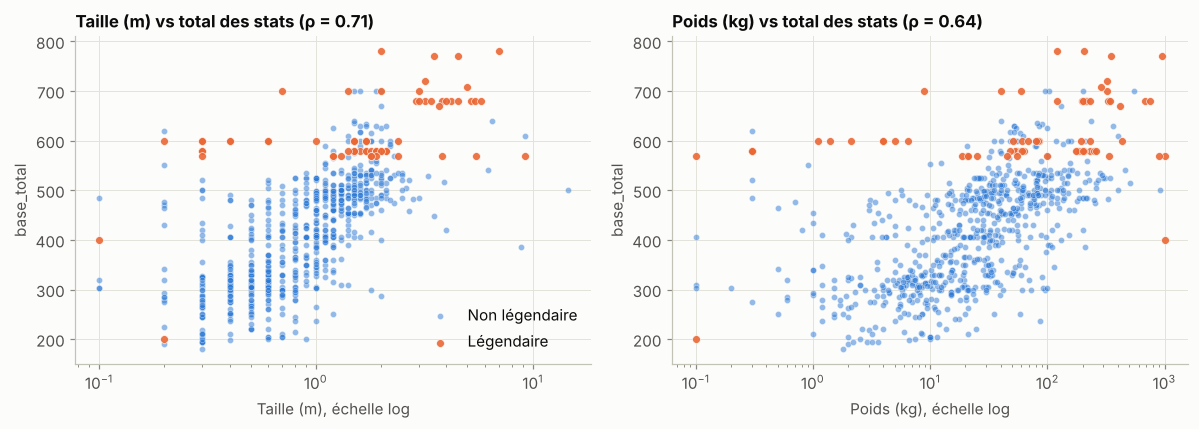

Asymétrie : {'height_m': 5.1, 'weight_kg': 4.9}


,height_m,weight_kg
is_legendary,,
Non légendaire,0.9,24.95
Légendaire,1.8,120.00


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, lab in zip(axes, PHYSICAL, ["Taille (m), échelle log", "Poids (kg), échelle log"]):
    for k in (0, 1):
        sub = df[df[TARGET_LEGENDARY] == k]
        ax.scatter(sub[col], sub["base_total"], s=16 if k == 0 else 26, color=LEG_PALETTE[k],
                   alpha=0.5 if k == 0 else 0.9, edgecolor="white", linewidth=0.4,
                   label=LEG_LABELS[k])
    ax.set_xscale("log")
    rho = df[[col, "base_total"]].corr(method="spearman").iloc[0, 1]
    ax.set(xlabel=lab, ylabel="base_total", title=f"{lab.split(',')[0]} vs total des stats (ρ = {rho:.2f})")
axes[0].legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "11_taille_poids")
plt.show()

print("Asymétrie :", df[PHYSICAL].skew().round(1).to_dict())
df.groupby(TARGET_LEGENDARY)[PHYSICAL].median().rename(index=LEG_LABELS)

**Lecture**

- La taille et le poids sont **extrêmement asymétriques** (asymétrie autour de 5) : le poids va de 0,1 kg à 999,9 kg. On les passera donc en **logarithme** $\log(1 + x)$ avant de les standardiser. Sans cela, quelques géants (Cosmovum et Bamboiselle à 999,9 kg, Groudon à 950 kg) écraseraient la distance.
- Les légendaires sont **plus grands** (1,8 m contre 0,9 m en médiane) et **plus lourds** (120 kg contre 25 kg). Ces deux variables sont aussi corrélées aux stats : avec le total, ρ = 0,71 pour la taille et 0,64 pour le poids. Elles apportent donc un peu d'information, mais en partie **redondante**. L'étape 3 mesurera si elles améliorent réellement la prédiction.

### 1.8 Synthèse de l'exploration

| Constat | Conséquence pour la modélisation |
|---|---|
| Stats sur des échelles différentes, distributions asymétriques | **Standardisation** (z-score) obligatoire pour K-means, k-NN, SVM et la régression logistique |
| Valeurs extrêmes réelles (Leuphorie, Caratroc) | On les **garde**. Les méthodes de rang (Spearman) et les arbres y sont robustes |
| Corrélations toutes positives (facteur de « puissance ») | La 1ʳᵉ composante de l'ACP = puissance globale. Le clustering séparera probablement les Pokémon faibles des forts, puis par profil |
| Défense et Vitesse indépendantes, Attaque et Att. Spé. peu corrélées | Axes physique/spécial et lent/rapide : base des **noms de clusters** |
| 8,7 % de légendaires | **Stratification**, métriques adaptées au déséquilibre, `class_weight` ou SMOTE |
| Chevauchement avec les pseudo-légendaires | Afficher une **probabilité** (bien calibrée) plutôt qu'un oui/non |
| 18 types déséquilibrés, Vol = 3 exemples | Traitement des types rares, F1 **macro**, top-3 accuracy |
| Eau et Normal sans signature statistique | Précision du type attendue modeste : analyser type par type |
| Taille et poids très asymétriques, 20 valeurs manquantes | `log1p` + imputation par la médiane **dans le pipeline** (variante) |
| Colonnes qui trichent (`capture_rate`, `base_egg_steps`, `against_*`…) | **Exclues** : seules les 6 stats servent d'entrée |